# Phase 4 — Exploratory Data Analysis (EDA)
## Australian Stock Market Analytics

Explore the 53-company cross-sectional dataset through distributions, rankings, price-position features, and correlations.

**Important:** This is not a historical time series. Correlation does not imply causation. Negative EPS/P-E values are retained. Missing values and WOW's invalid 52-week range are not fabricated or silently imputed.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme()
print("Imports successful.")

Imports successful.


## 2. Load Phase 3 dataset

In [2]:
INPUT_FILENAME = "australian_stocks_feature_engineered.csv"
PROJECT_ROOT = None
input_file = None

for base in [Path.cwd(), *Path.cwd().parents]:
    candidate = base / "data" / "processed" / INPUT_FILENAME
    if candidate.exists():
        PROJECT_ROOT, input_file = base, candidate
        break

if input_file is None:
    raise FileNotFoundError(
        f"Cannot find {INPUT_FILENAME}. Run Phase 3 and save it in data/processed/."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
EDA_DIR = PROJECT_ROOT / "reports" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(input_file)

print("Input:", input_file)
print("Shape:", df.shape)
print("Unique tickers:", df["ticker"].nunique())
display(df.head())

Input: e:\Projects\Australian Stock Market Data Science Project\data\processed\australian_stocks_feature_engineered.csv
Shape: (53, 47)
Unique tickers: 53


,ticker,company_name,total_shares,market_cap_m,eps_2h2024,eps_1h2025,eps_ltm,eps_ap_24_25,pe_annual_report,pe_ltm,price,book_value_per_share,week52_range,duplicate_ticker_flag,annual_pe_missing,week52_low,week52_high,market_cap_m_original,eps_ltm_original,pe_ltm_original,total_shares_outlier,market_cap_m_outlier,eps_ltm_outlier,eps_ap_24_25_outlier,pe_ltm_outlier,price_outlier,book_value_per_share_outlier,week52_range_valid,log_market_cap_m,market_cap_size_band,eps_half_year_difference,eps_ltm_vs_annual_difference,eps_ltm_vs_annual_pct_difference,earnings_yield_pct,price_to_book,pe_ltm_minus_annual,pe_ltm_vs_annual_pct_difference,week52_range_width,price_position_52w,price_distance_from_52w_low_pct,price_distance_from_52w_high_pct,price_outside_52w_range,annual_pe_missing_flag,negative_ltm_eps_flag,negative_ltm_pe_flag,nonpositive_book_value_flag,invalid_52w_range_flag
0,VEA,Viva Energy Group Ltd,1625651926,"3,511.408",-0.300,12.300,12.000,4.800,450.000,18.000,2.160,1.027,1.41 - 2.83,False,False,1.410,2.830,"3,511.408",12.000,18.000,False,False,False,False,False,False,False,True,8.164,Medium (sample-relative),12.600,7.200,150.000,5.556,2.103,-432.000,-96.000,1.420,0.528,53.191,23.675,False,False,False,False,False,False
1,DDR,Dicker Data Ltd,180817855,"1,871.465",23.970,21.790,45.760,43.620,237.276,22.618,10.350,1.389,7.58 - 10.94,False,False,7.580,10.940,"1,871.465",45.760,22.618,False,False,False,False,False,False,False,True,7.534,Medium (sample-relative),-2.180,2.140,4.906,4.421,7.451,-214.658,-90.468,3.360,0.824,36.544,5.393,False,False,False,False,False,False
2,FMG,Fortescue Metals Group Ltd,3078964918,"68,075.914",50.500,39.550,90.050,109.700,201.550,24.553,22.110,9.874,13.18 - 22.11,False,False,13.180,22.110,"68,075.914",90.050,24.553,True,True,False,False,False,False,False,True,11.128,Large (sample-relative),-10.950,-19.650,-17.912,4.073,2.239,-176.997,-87.818,8.930,1.000,67.754,0.000,False,False,False,False,False,False
3,RIO,RIO Tinto Ltd,371216214,"51,402.309",315.200,296.000,611.200,669.500,206.826,22.655,138.470,54.474,100.75 - 140.58,False,False,100.750,140.580,"51,402.309",611.200,22.655,False,True,True,True,False,True,True,True,10.847,Large (sample-relative),-19.200,-58.300,-8.708,4.414,2.542,-184.171,-89.046,39.830,0.947,37.439,1.501,False,False,False,False,False,False
4,APE,Eagers Automotive Ltd,282364338,"7,578.659",34.800,46.400,81.200,80.200,334.663,33.054,26.840,4.636,10.90 - 35.64,False,False,10.900,35.640,"7,578.659",81.200,33.054,False,False,False,False,False,False,False,True,8.933,Medium (sample-relative),11.600,1.000,1.247,3.025,5.789,-301.609,-90.123,24.740,0.644,146.239,24.691,False,False,False,False,False,False


## 3. Validate schema and numeric columns

In [3]:
required = [
    "ticker", "company_name", "market_cap_m", "eps_ltm", "eps_ap_24_25",
    "pe_ltm", "pe_annual_report", "price", "book_value_per_share",
    "price_to_book", "price_position_52w", "week52_low", "week52_high"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing expected columns: {missing}")
if df["ticker"].duplicated().any():
    raise ValueError("Duplicate tickers found. Recheck Phase 2/3.")

numeric_cols = [
    "total_shares", "market_cap_m", "eps_2h2024", "eps_1h2025", "eps_ltm",
    "eps_ap_24_25", "pe_annual_report", "pe_ltm", "price",
    "book_value_per_share", "price_to_book", "earnings_yield_pct",
    "price_position_52w", "week52_low", "week52_high",
    "price_distance_from_52w_low_pct", "price_distance_from_52w_high_pct"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Schema validation passed.")
print("Rows:", len(df), "| Unique tickers:", df["ticker"].nunique())
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

Schema validation passed.
Rows: 53 | Unique tickers: 53


,missing_count
pe_annual_report,2
pe_ltm_vs_annual_pct_difference,2
pe_ltm_minus_annual,2
week52_high,1
week52_low,1
earnings_yield_pct,1
week52_range_width,1
price_position_52w,1
price_outside_52w_range,1
price_distance_from_52w_high_pct,1


## 4. Descriptive statistics

In [4]:
desc_cols = [
    c for c in [
        "total_shares", "market_cap_m", "eps_ltm", "eps_ap_24_25",
        "pe_ltm", "pe_annual_report", "price", "book_value_per_share",
        "price_to_book", "earnings_yield_pct", "price_position_52w"
    ] if c in df.columns
]
desc = df[desc_cols].describe().T
desc["median"] = df[desc_cols].median()
desc["missing"] = df[desc_cols].isna().sum()
display(desc)
desc.to_csv(EDA_DIR / "eda_descriptive_statistics.csv")

,count,mean,std,min,25%,50%,75%,max,median,missing
total_shares,53.000,"989,834,970.434","1,741,828,422.656","68,152,321.000","185,340,291.000","305,377,396.000","1,221,597,320.000","11,543,702,836.000","305,377,396.000",0
market_cap_m,53.000,"22,267.239","46,043.105",7.671,553.091,"3,484.503","18,330.950","255,604.641","3,484.503",0
eps_ltm,53.000,125.182,271.388,-36.700,11.400,27.200,96.500,"1,560.000",27.200,0
eps_ap_24_25,53.000,127.174,272.116,0.390,11.400,27.730,98.200,"1,560.000",27.730,0
pe_ltm,53.000,40.208,120.600,-88.474,12.089,18.648,28.279,866.667,18.648,0
pe_annual_report,51.000,445.811,"1,215.022",9.196,132.513,190.443,313.444,"8,666.667",190.443,2
price,53.000,22.525,39.543,0.045,2.250,7.750,22.110,196.350,7.750,0
book_value_per_share,53.000,8.956,15.563,0.060,1.097,3.535,9.766,90.678,3.535,0
price_to_book,53.000,2.611,2.202,0.284,1.165,1.811,2.948,10.010,1.811,0
earnings_yield_pct,52.000,11.310,20.865,0.115,3.480,5.332,7.787,108.745,5.332,1


## 5. Market-cap distribution

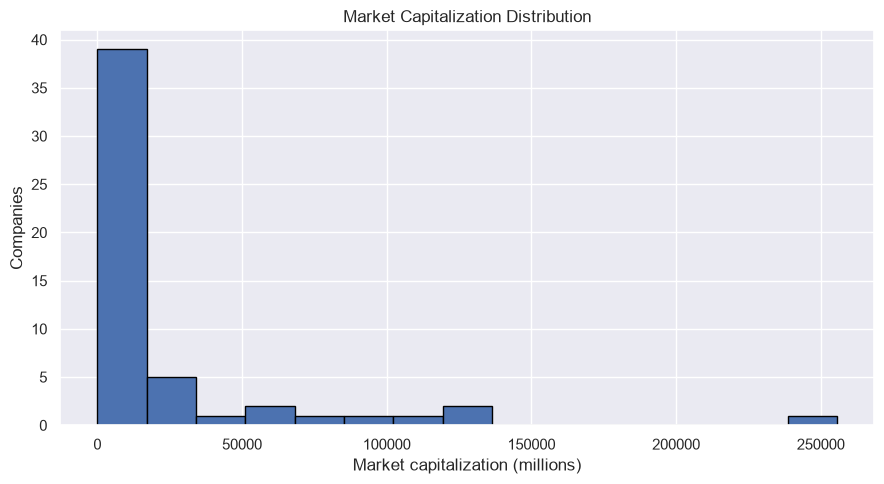

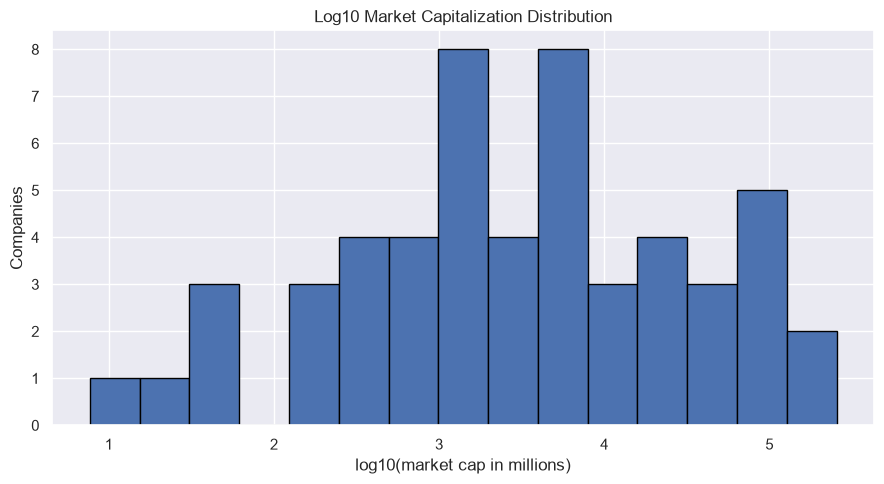

In [5]:
values = df.loc[df["market_cap_m"] > 0, "market_cap_m"].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(values, bins=15, edgecolor="black")
ax.set(title="Market Capitalization Distribution", xlabel="Market capitalization (millions)", ylabel="Companies")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(np.log10(values), bins=15, edgecolor="black")
ax.set(title="Log10 Market Capitalization Distribution", xlabel="log10(market cap in millions)", ylabel="Companies")
plt.tight_layout()
plt.show()

## 6. Top 10 companies by market capitalization

,ticker,company_name,market_cap_m
22,CBA,Commonwealth Bank of Australia,"255,604.641"
23,WBC,Westpac Banking Corporation,"130,862.717"
24,NAB,National Australia Bank Ltd,"126,788.980"
30,ANZ,Australia and New Zealand Banking Group Ltd,"105,669.603"
45,WES,Wesfarmers Ltd,"91,923.086"
25,MQG,Macquarie Group Limited,"74,836.528"
2,FMG,Fortescue Metals Group Ltd,"68,075.914"
3,RIO,RIO Tinto Ltd,"51,402.309"
37,WOW,Woolworths Group Ltd,"35,902.745"
48,SIG,Sigma Healthcare Ltd,"33,245.864"


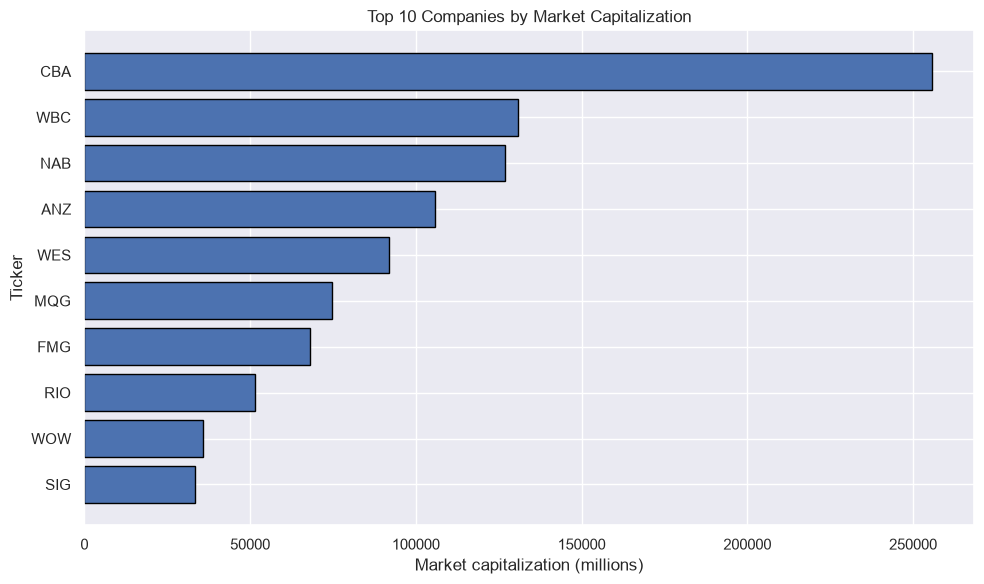

In [6]:
top_cap = df.nlargest(10, "market_cap_m")[["ticker", "company_name", "market_cap_m"]].sort_values("market_cap_m")
display(top_cap.sort_values("market_cap_m", ascending=False))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_cap["ticker"], top_cap["market_cap_m"], edgecolor="black")
ax.set(title="Top 10 Companies by Market Capitalization", xlabel="Market capitalization (millions)", ylabel="Ticker")
plt.tight_layout()
plt.show()
top_cap.to_csv(EDA_DIR / "top_10_market_cap.csv", index=False)

## 7. LTM EPS distribution and negative EPS

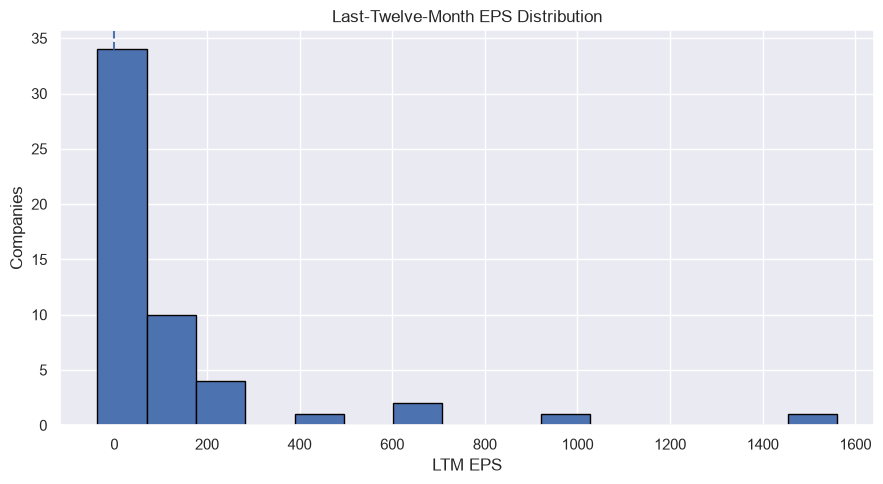

Companies with negative LTM EPS: 1


,ticker,company_name,eps_ltm,pe_ltm
51,ALD,Ampol Ltd,-36.700,-88.474


In [7]:
eps = df["eps_ltm"].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(eps, bins=15, edgecolor="black")
ax.axvline(0, linestyle="--")
ax.set(title="Last-Twelve-Month EPS Distribution", xlabel="LTM EPS", ylabel="Companies")
plt.tight_layout()
plt.show()

negative_eps = df.loc[df["eps_ltm"] < 0, ["ticker", "company_name", "eps_ltm", "pe_ltm"]].sort_values("eps_ltm")
print("Companies with negative LTM EPS:", len(negative_eps))
display(negative_eps)
negative_eps.to_csv(EDA_DIR / "companies_negative_ltm_eps.csv", index=False)

## 8. Compare the two half-year EPS values
This comparison is descriptive and does not automatically indicate a growth trend; seasonality and reporting context matter.

,ticker,eps_2h2024,eps_1h2025,eps_half_year_difference
10,ORA,67.700,-56.300,-124.000
25,MQG,554.800,436.700,-118.100
43,JBH,261.100,161.900,-99.200
29,BEN,38.300,-21.100,-59.400
30,ANZ,122.500,72.200,-50.300
37,WOW,60.500,18.400,-42.100
38,BRG,67.800,26.600,-41.200
15,GNC,26.200,-8.000,-34.200
44,CFK,20.500,-13.000,-33.500
42,NTD,28.840,-1.110,-29.950


,ticker,eps_2h2024,eps_1h2025,eps_half_year_difference
27,SUN,86.560,"1,473.440","1,386.880"
51,ALD,-47.300,10.600,57.900
47,ANN,37.800,88.300,50.500
52,WPR,5.680,20.490,14.810
0,VEA,-0.300,12.300,12.600
4,APE,34.800,46.400,11.600
16,SGLLV,47.200,55.700,8.500
20,KMD,3.000,10.400,7.400
7,ASG,5.160,11.100,5.940
9,ACL,5.830,11.320,5.490


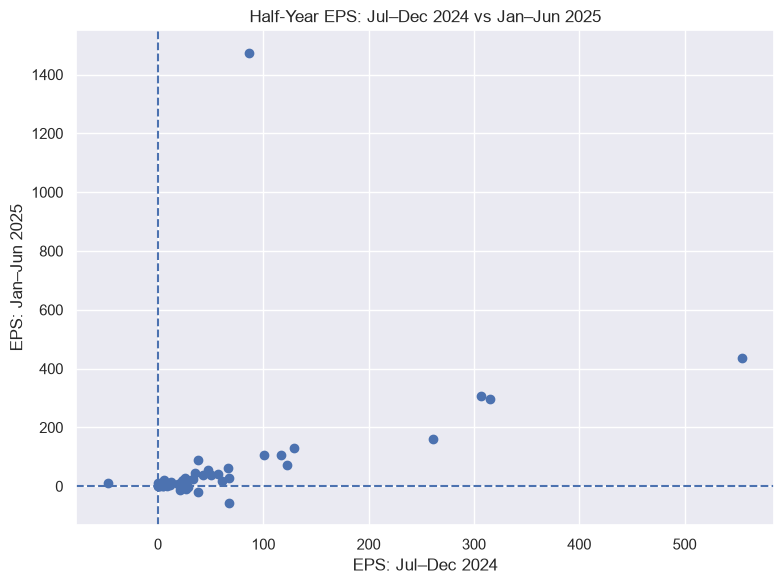

In [8]:
eps_cols = ["ticker", "eps_2h2024", "eps_1h2025", "eps_half_year_difference"]
display(df[eps_cols].sort_values("eps_half_year_difference").head(10))
display(df[eps_cols].sort_values("eps_half_year_difference", ascending=False).head(10))

plot_df = df.dropna(subset=["eps_2h2024", "eps_1h2025"])
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(plot_df["eps_2h2024"], plot_df["eps_1h2025"])
ax.axhline(0, linestyle="--")
ax.axvline(0, linestyle="--")
ax.set(title="Half-Year EPS: Jul–Dec 2024 vs Jan–Jun 2025", xlabel="EPS: Jul–Dec 2024", ylabel="EPS: Jan–Jun 2025")
plt.tight_layout()
plt.show()

## 9. LTM P/E distribution
P/E can be negative or extreme when earnings are negative or near zero. The full distribution and positive-P/E distribution are shown separately.

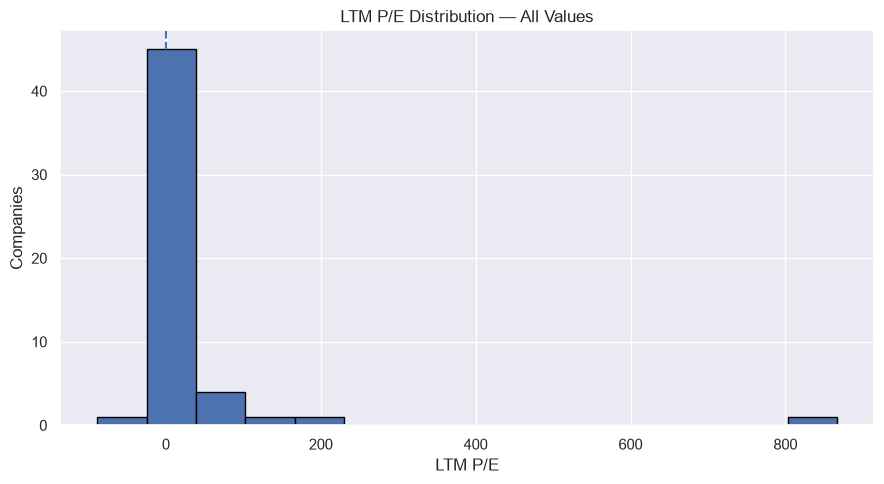

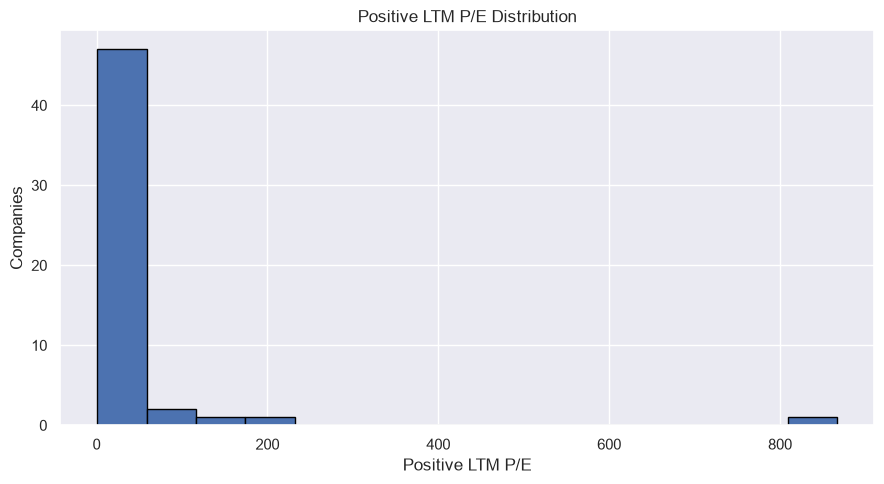

Negative P/E: 1
Zero P/E: 0
Missing P/E: 0


In [9]:
pe = df["pe_ltm"].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(pe, bins=15, edgecolor="black")
ax.axvline(0, linestyle="--")
ax.set(title="LTM P/E Distribution — All Values", xlabel="LTM P/E", ylabel="Companies")
plt.tight_layout()
plt.show()

positive_pe = df.loc[df["pe_ltm"] > 0, "pe_ltm"].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(positive_pe, bins=15, edgecolor="black")
ax.set(title="Positive LTM P/E Distribution", xlabel="Positive LTM P/E", ylabel="Companies")
plt.tight_layout()
plt.show()

print("Negative P/E:", int((df["pe_ltm"] < 0).sum()))
print("Zero P/E:", int((df["pe_ltm"] == 0).sum()))
print("Missing P/E:", int(df["pe_ltm"].isna().sum()))

## 10. LTM P/E vs annual-report P/E

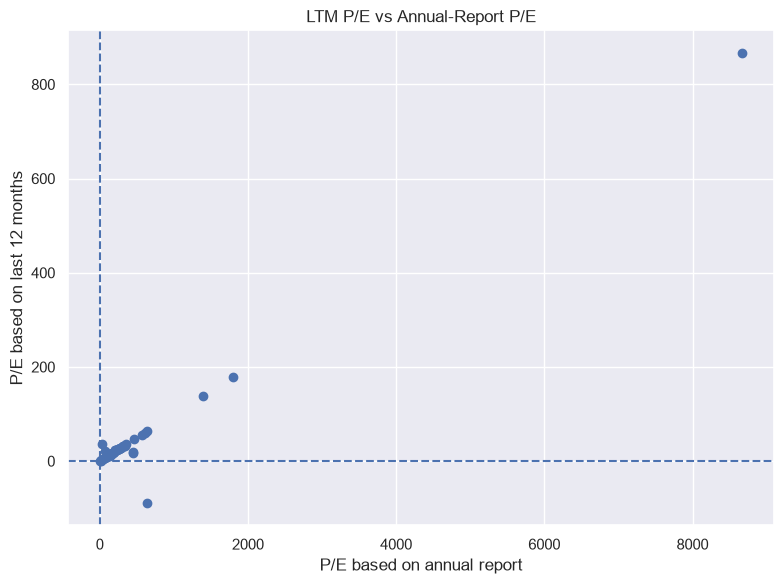

Companies included: 51 of 53


In [10]:
pe_compare = df.dropna(subset=["pe_ltm", "pe_annual_report"])
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pe_compare["pe_annual_report"], pe_compare["pe_ltm"])
ax.axhline(0, linestyle="--")
ax.axvline(0, linestyle="--")
ax.set(title="LTM P/E vs Annual-Report P/E", xlabel="P/E based on annual report", ylabel="P/E based on last 12 months")
plt.tight_layout()
plt.show()
print(f"Companies included: {len(pe_compare)} of {len(df)}")

## 11. Share price vs book value

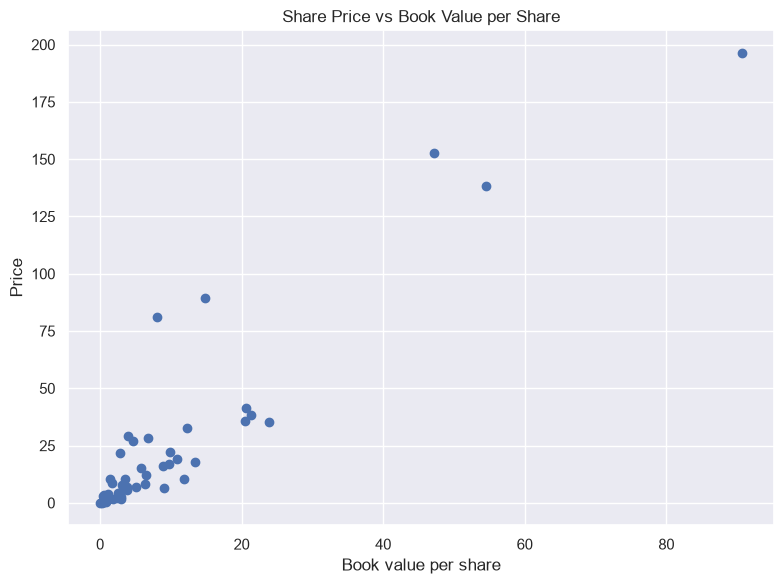

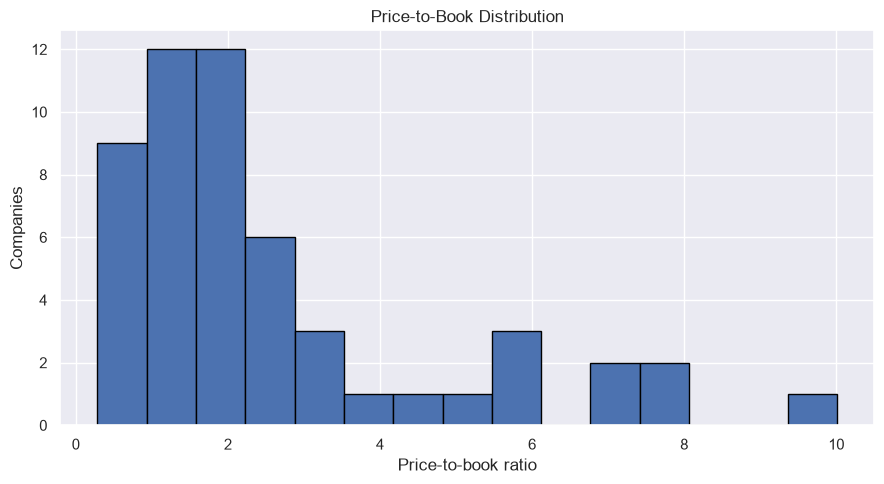

In [11]:
pb = df.dropna(subset=["price", "book_value_per_share", "price_to_book"])
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pb["book_value_per_share"], pb["price"])
ax.set(title="Share Price vs Book Value per Share", xlabel="Book value per share", ylabel="Price")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(pb["price_to_book"], bins=15, edgecolor="black")
ax.set(title="Price-to-Book Distribution", xlabel="Price-to-book ratio", ylabel="Companies")
plt.tight_layout()
plt.show()

## 12. Current price within 52-week range

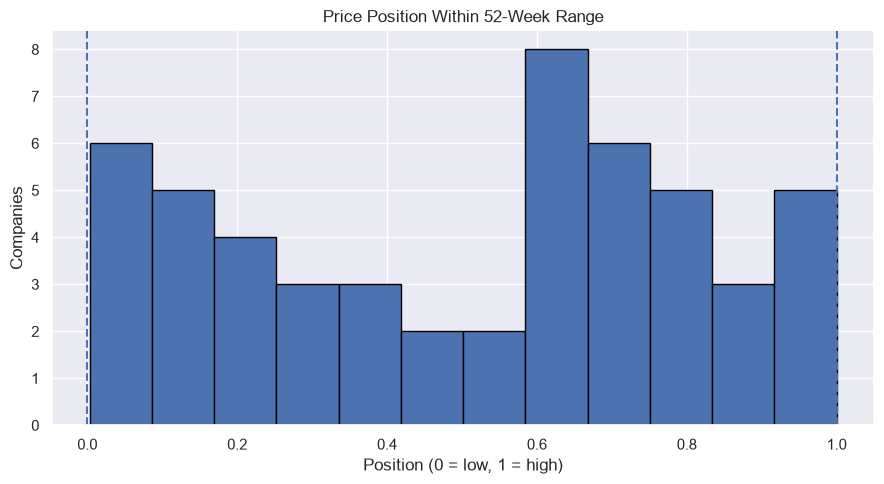

,ticker,company_name,price,week52_low,week52_high,price_position_52w,price_outside_52w_range
21,AX1,Accent Group Ltd,0.920,0.915,2.460,0.003,False
40,ADH,Adairs Ltd,1.765,1.745,2.990,0.016,False
50,STP,Step One Clothing Ltd,0.320,0.260,1.450,0.050,False
36,PTL,Pental Ltd,0.045,0.041,0.097,0.071,False
13,GAP,Gale Pacific Ltd,0.090,0.086,0.140,0.074,False
27,SUN,Suncorp Group Ltd,17.070,16.630,22.140,0.080,False
31,BOQ,Bank of Queensland Ltd,6.450,6.200,8.160,0.128,False
26,QBE,QBE Insurance Group Limited,19.150,18.340,24.200,0.138,False
19,KGN,Kogan.com Ltd,3.380,2.880,6.370,0.143,False
49,REH,Reece Ltd,12.330,10.140,24.600,0.151,False


In [12]:
position = df["price_position_52w"].dropna()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(position, bins=12, edgecolor="black")
ax.axvline(0, linestyle="--")
ax.axvline(1, linestyle="--")
ax.set(title="Price Position Within 52-Week Range", xlabel="Position (0 = low, 1 = high)", ylabel="Companies")
plt.tight_layout()
plt.show()

position_table = df[[
    "ticker", "company_name", "price", "week52_low", "week52_high",
    "price_position_52w", "price_outside_52w_range"
]].sort_values("price_position_52w", na_position="last")
display(position_table)
position_table.to_csv(EDA_DIR / "price_position_52w.csv", index=False)

## 13. Pearson and Spearman correlation
Pearson captures linear association; Spearman captures monotonic rank association. Pairwise available values are used. Correlation does not imply causation.

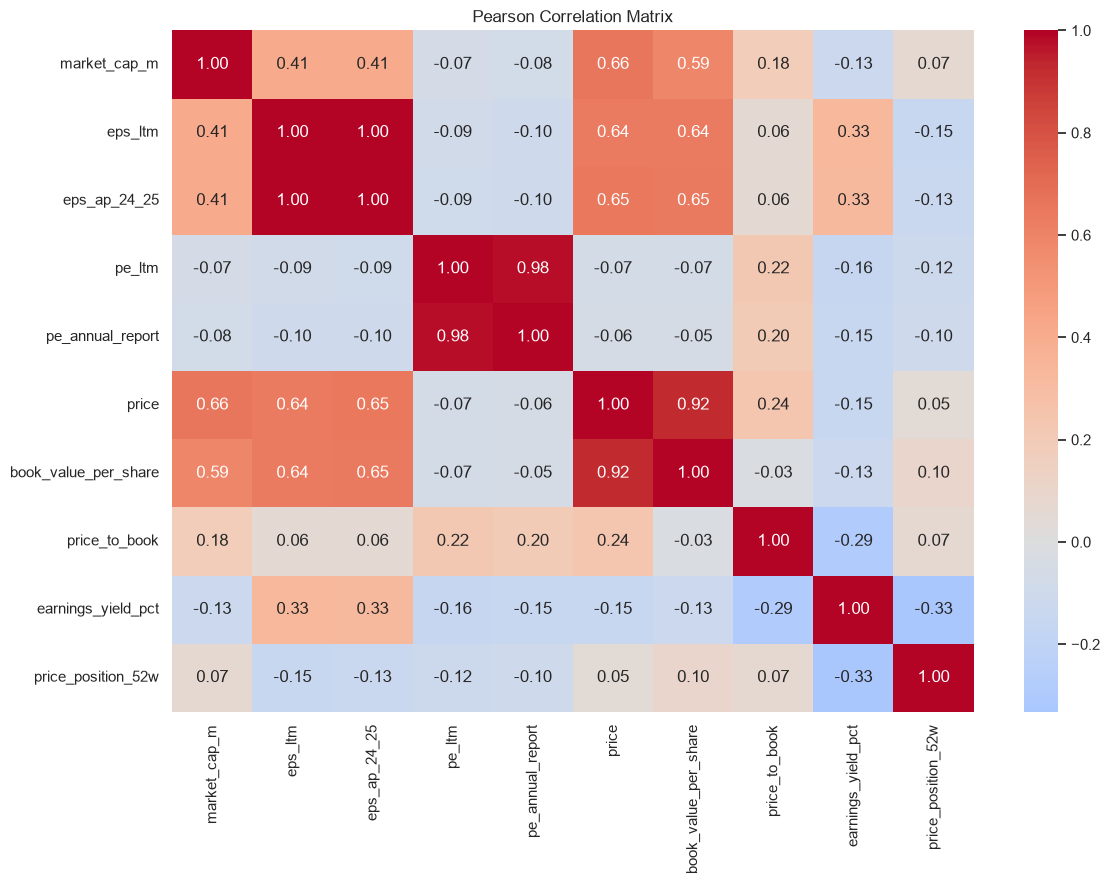

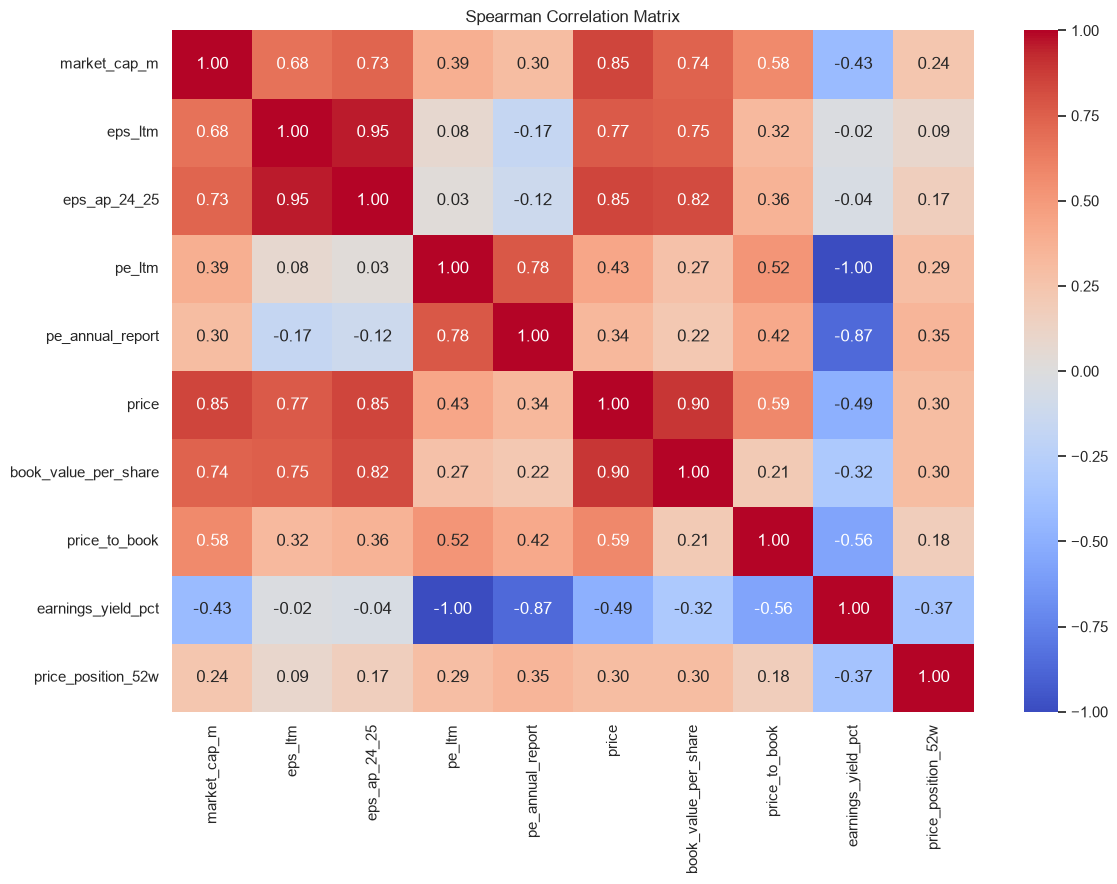

In [13]:
corr_cols = [
    c for c in [
        "market_cap_m", "eps_ltm", "eps_ap_24_25", "pe_ltm",
        "pe_annual_report", "price", "book_value_per_share",
        "price_to_book", "earnings_yield_pct", "price_position_52w"
    ] if c in df.columns
]
corr_data = df[corr_cols]
pearson = corr_data.corr(method="pearson")
spearman = corr_data.corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

pearson.to_csv(EDA_DIR / "pearson_correlation_matrix.csv")
spearman.to_csv(EDA_DIR / "spearman_correlation_matrix.csv")

## 14. Selected financial relationships
These plots explore associations, not causal effects.

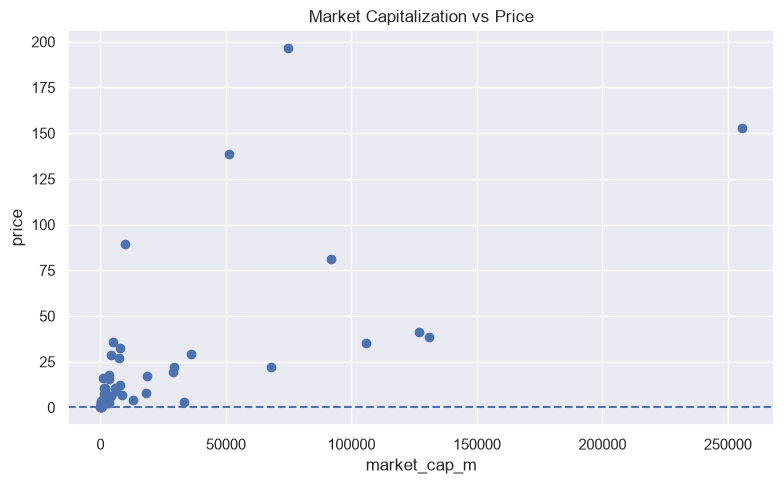

Market Capitalization vs Price: n=53


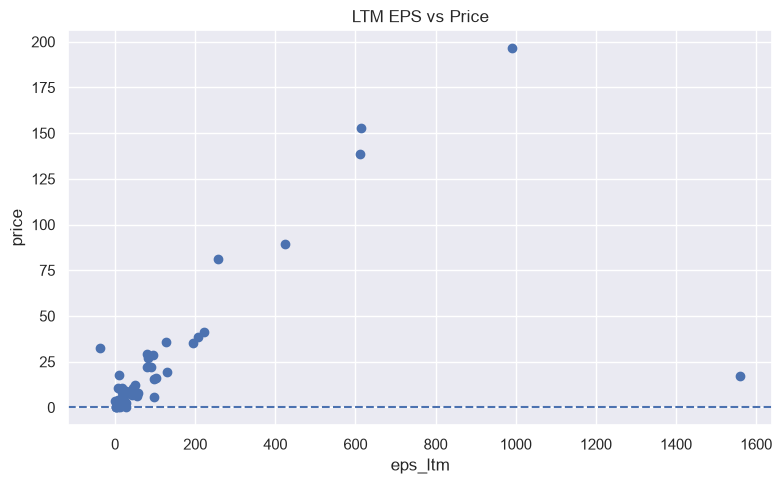

LTM EPS vs Price: n=53


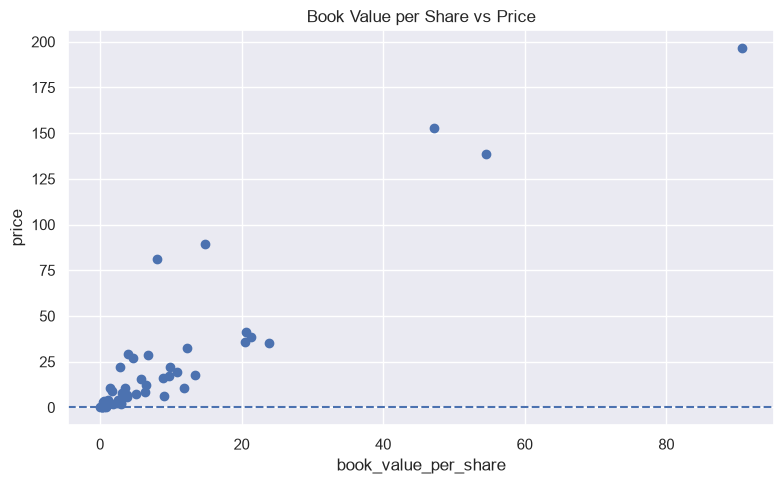

Book Value per Share vs Price: n=53


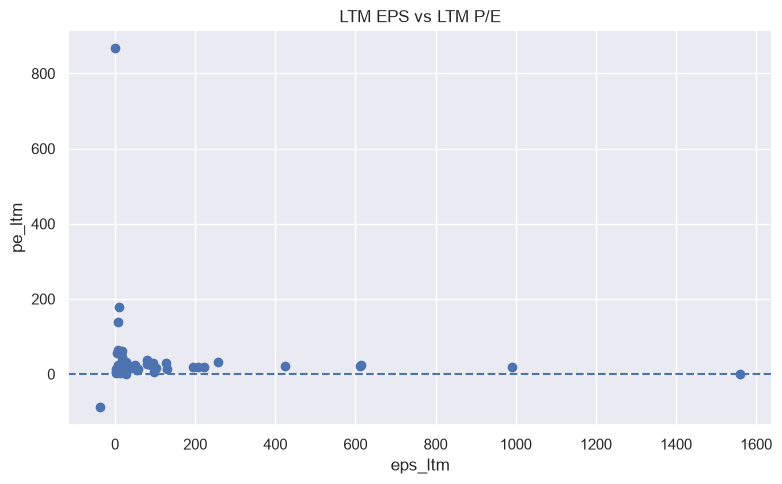

LTM EPS vs LTM P/E: n=53


In [14]:
pairs = [
    ("market_cap_m", "price", "Market Capitalization vs Price"),
    ("eps_ltm", "price", "LTM EPS vs Price"),
    ("book_value_per_share", "price", "Book Value per Share vs Price"),
    ("eps_ltm", "pe_ltm", "LTM EPS vs LTM P/E")
]
for x, y, title in pairs:
    sample = df[[x, y]].dropna()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(sample[x], sample[y])
    ax.axhline(0, linestyle="--")
    ax.set(title=title, xlabel=x, ylabel=y)
    plt.tight_layout()
    plt.show()
    print(f"{title}: n={len(sample)}")

## 15. Descriptive rankings
Rankings summarize the sample and are not buy/sell recommendations.

In [15]:
ranking_specs = [
    ("market_cap_m", "top_market_cap"),
    ("eps_ltm", "highest_ltm_eps"),
    ("price", "highest_share_price"),
    ("price_to_book", "highest_price_to_book"),
    ("pe_ltm", "highest_positive_ltm_pe")
]
for col, filename in ranking_specs:
    ranked = df.loc[df[col].notna()].copy()
    if col == "pe_ltm":
        ranked = ranked.loc[ranked[col] > 0]
    ranked = ranked.nlargest(10, col)[["ticker", "company_name", col]]
    print(f"\nTop 10 by {col}")
    display(ranked)
    ranked.to_csv(EDA_DIR / f"{filename}.csv", index=False)


Top 10 by market_cap_m


,ticker,company_name,market_cap_m
22,CBA,Commonwealth Bank of Australia,"255,604.641"
23,WBC,Westpac Banking Corporation,"130,862.717"
24,NAB,National Australia Bank Ltd,"126,788.980"
30,ANZ,Australia and New Zealand Banking Group Ltd,"105,669.603"
45,WES,Wesfarmers Ltd,"91,923.086"
25,MQG,Macquarie Group Limited,"74,836.528"
2,FMG,Fortescue Metals Group Ltd,"68,075.914"
3,RIO,RIO Tinto Ltd,"51,402.309"
37,WOW,Woolworths Group Ltd,"35,902.745"
48,SIG,Sigma Healthcare Ltd,"33,245.864"



Top 10 by eps_ltm


,ticker,company_name,eps_ltm
27,SUN,Suncorp Group Ltd,"1,560.000"
25,MQG,Macquarie Group Limited,991.500
22,CBA,Commonwealth Bank of Australia,613.200
3,RIO,RIO Tinto Ltd,611.200
43,JBH,JB Hi-Fi Ltd,423.000
45,WES,Wesfarmers Ltd,258.000
24,NAB,National Australia Bank Ltd,221.900
23,WBC,Westpac Banking Corporation,206.300
30,ANZ,Australia and New Zealand Banking Group Ltd,194.700
26,QBE,QBE Insurance Group Limited,129.400



Top 10 by price


,ticker,company_name,price
25,MQG,Macquarie Group Limited,196.350
22,CBA,Commonwealth Bank of Australia,152.740
3,RIO,RIO Tinto Ltd,138.470
43,JBH,JB Hi-Fi Ltd,89.410
45,WES,Wesfarmers Ltd,81.020
24,NAB,National Australia Bank Ltd,41.380
23,WBC,Westpac Banking Corporation,38.260
47,ANN,Ansell Ltd,35.660
30,ANZ,Australia and New Zealand Banking Group Ltd,35.390
51,ALD,Ampol Ltd,32.470



Top 10 by price_to_book


,ticker,company_name,price_to_book
45,WES,Wesfarmers Ltd,10.010
33,COL,Coles Group Limited,7.701
1,DDR,Dicker Data Ltd,7.451
37,WOW,Woolworths Group Ltd,7.388
48,SIG,Sigma Healthcare Ltd,7.094
43,JBH,JB Hi-Fi Ltd,6.047
4,APE,Eagers Automotive Ltd,5.789
19,KGN,Kogan.com Ltd,5.578
34,A2M,a2 Milk Company Ltd,5.026
38,BRG,Breville Group Ltd,4.241



Top 10 by pe_ltm


,ticker,company_name,pe_ltm
19,KGN,Kogan.com Ltd,866.667
8,SGM,Sims Ltd,179.495
44,CFK,Collins Foods Ltd,138.933
18,PLS,Pilbara Minerals Ltd,64.297
29,BEN,Bendigo and Adelaide Bank Ltd,60.523
48,SIG,Sigma Healthcare Ltd,56.471
15,GNC,Graincorp Ltd,45.934
37,WOW,Woolworths Group Ltd,37.250
35,BGA,Bega Cheese Ltd,35.482
4,APE,Eagers Automotive Ltd,33.054


## 16. Missingness and quality flags

In [16]:
missing_summary = df.isna().sum().sort_values(ascending=False)
missing_summary = missing_summary[missing_summary > 0].rename("missing_count").to_frame()
display(missing_summary)

quality_cols = [
    c for c in [
        "annual_pe_missing_flag", "negative_ltm_eps_flag", "negative_ltm_pe_flag",
        "invalid_52w_range_flag", "price_outside_52w_range"
    ] if c in df.columns
]
quality_counts = {
    col: int(df[col].fillna(False).astype(bool).sum())
    for col in quality_cols
}
quality_summary = pd.Series(quality_counts, name="count").to_frame()
display(quality_summary)

missing_summary.to_csv(EDA_DIR / "eda_missingness_summary.csv")
quality_summary.to_csv(EDA_DIR / "eda_quality_flag_summary.csv")

,missing_count
pe_annual_report,2
pe_ltm_vs_annual_pct_difference,2
pe_ltm_minus_annual,2
week52_high,1
week52_low,1
earnings_yield_pct,1
week52_range_width,1
price_position_52w,1
price_outside_52w_range,1
price_distance_from_52w_high_pct,1


,count
annual_pe_missing_flag,2
negative_ltm_eps_flag,1
negative_ltm_pe_flag,1
invalid_52w_range_flag,1
price_outside_52w_range,0


## 17. Save EDA summary

In [17]:
summary = pd.DataFrame([{
    "rows": len(df),
    "unique_tickers": df["ticker"].nunique(),
    "duplicate_tickers": int(df["ticker"].duplicated().sum()),
    "missing_annual_pe": int(df["pe_annual_report"].isna().sum()),
    "invalid_52w_ranges": int(df["invalid_52w_range_flag"].sum()),
    "negative_ltm_eps": int((df["eps_ltm"] < 0).sum()),
    "negative_ltm_pe": int((df["pe_ltm"] < 0).sum()),
    "companies_with_price_position": int(df["price_position_52w"].notna().sum())
}])
display(summary)
summary.to_csv(EDA_DIR / "eda_summary.csv", index=False)
print("EDA outputs saved to:", EDA_DIR)
print("PHASE 4 EDA COMPLETED — review charts and tables before Phase 5.")

,rows,unique_tickers,duplicate_tickers,missing_annual_pe,invalid_52w_ranges,negative_ltm_eps,negative_ltm_pe,companies_with_price_position
0,53,53,0,2,1,1,1,52


EDA outputs saved to: e:\Projects\Australian Stock Market Data Science Project\reports\eda
PHASE 4 EDA COMPLETED — review charts and tables before Phase 5.
